# Problem 3 Pipeline: Top-Bracket Bunching, Pareto Calibration, and MVPF
Reproducible pipeline for Section 3 (`report/sections/03.tex`).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from utils import load_root
ROOT = load_root()

from source.bunching.loader import load_counts, pool_counts
from source.bunching.model import estimate
from source.bunching.mvpf import (
    PS1_PARETO_ALPHAS,
    calibrate_mvpf_table,
    estimate_pareto_alpha_binned,
)
from source.plots import FIGURES_DIR, save_fig
from source.plots.p3 import plot_top_bracket_bunching, plot_mvpf_calibration


[utils] Project root loaded successfully: /home/choroy/Documents/doctorado/S4/ENECO894/problem-set-2


## 1. Top-Bracket Bunching on `synthetic_bunch_counts.csv`

In [2]:
synth_path = ROOT / "data/synthetic_bunch_counts.csv"
thr_path = ROOT / "data/threshold.csv"

z23, c23 = load_counts(str(synth_path), year=2023)
thr_map = pd.read_csv(thr_path).set_index("year")["threshold_clp"].to_dict()
years = sorted(thr_map.keys())
counts_all = {y: load_counts(str(synth_path), year=y) for y in years}

z_150_bench = (150.0 / 13.5) * 9_907_434
z_150_dec = (150.0 / 13.5) * 10_402_932
z_150_mode = 113_500_000.0
z_120_bench = (120.0 / 13.5) * 9_907_434

fit_150_mode = estimate(z23, c23, z_150_mode, 80e6, 155e6, 110e6, 116e6, degree=4, tau0=0.35, tau1=0.40)
fit_150_bench = estimate(z23, c23, z_150_bench, 80e6, 155e6, 107e6, 113e6, degree=4, tau0=0.35, tau1=0.40)
fit_150_dec = estimate(z23, c23, z_150_dec, 80e6, 155e6, 112e6, 118e6, degree=4, tau0=0.35, tau1=0.40)
fit_120_bench = estimate(z23, c23, z_120_bench, 60e6, 130e6, 85e6, 91e6, degree=4, tau0=0.35, tau1=0.40)

scale_120 = {y: float(thr_map[y]) * (120.0 / 13.5) for y in years}
zp_120, cp_120 = pool_counts(counts_all, scale_120, width=0.01)
fit_pool_120 = estimate(zp_120, cp_120, 1.0, 0.65, 1.45, 0.90, 1.10, degree=4, tau0=0.35, tau1=0.40)
fit_kink1 = estimate(z23, c23, 9_907_434.0, 6.5e6, 20e6, 8.5e6, 10.5e6, degree=4, tau0=0.0, tau1=0.04)

bunch_df = pd.read_csv(ROOT / "output/tables/p3_bunching_specs.csv")
bunch_df[["spec_short", "B", "b_str", "epsilon"]]

,spec_short,B,b_str,epsilon
0,2023 150 UTA mode (113.5M),162.134293,"\$222,159",0.024454
1,2023 150 UTA bench (110.1M),109.282208,"\$136,725",0.015517
2,2023 150 UTA Dec (115.6M),146.390886,"\$212,386",0.022956
3,2023 120 UTA bench (88.1M),226.369759,"\$139,639",0.019810
4,Pooled 05-23 (120 UTA),3836.511611,0.0021 $K_{120}$,0.025978


saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set-2/output/figures/p3/p3_top_bunching.pdf


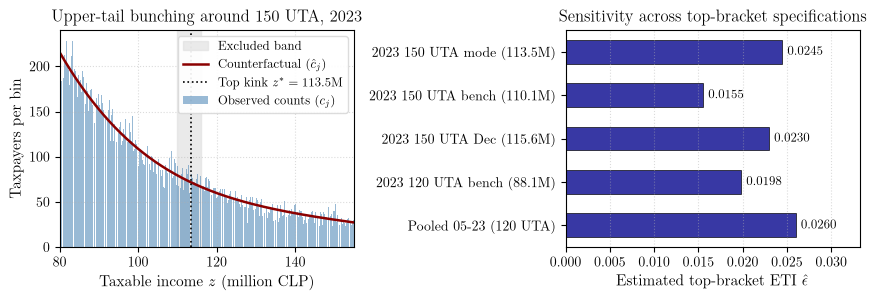

In [4]:
fig1, axes1 = plt.subplots(1, 2, figsize=(8.8, 3.1))
plot_top_bracket_bunching(
    z23, c23, fit_150_mode["c_hat"], z_150_mode, 110e6, 116e6, (80e6, 155e6),
    bunch_df, fig=fig1, axes=axes1
)
save_fig(FIGURES_DIR / "p3/p3_top_bunching.pdf", fig=fig1)
plt.show()

## 2. Calibration of Local and Average MVPF with Problem Set 1 Pareto Parameters

In [5]:
mvpf_df = pd.read_csv(ROOT / "output/tables/p3_mvpf_calibration.csv")
mvpf_df[["alpha_label", "epsilon", "alpha", "mvpf_tau0", "mvpf_tau1", "mvpf_midpoint", "mvpf_exact"]]

,alpha_label,epsilon,alpha,mvpf_tau0,mvpf_tau1,mvpf_midpoint,mvpf_exact
0,"PS1 Vermeulen MLE ($w_{\min}=380\text{M}$, $\h...",0.024454,1.859,1.031254,1.025093,1.028041,1.028085
1,"PS1 SII Top Bracket ($>310\text{ UTA}$, $\hat{...",0.024454,2.085,1.035187,1.028229,1.031557,1.031607
2,PS1 Gabaix--Ibragimov Reg ($w_{\min}=380\text{...,0.024454,2.135,1.036061,1.028926,1.032338,1.032390
3,"PS1 Vermeulen MLE ($w_{\min}=P99$, $\hat{\alph...",0.024454,2.531,1.043038,1.034476,1.038568,1.038631
4,"PS1 Vermeulen MLE ($w_{\min}=380\text{M}$, $\h...",0.015517,1.859,1.019608,1.015778,1.017612,1.017639
5,"PS1 SII Top Bracket ($>310\text{ UTA}$, $\hat{...",0.015517,2.085,1.022044,1.017730,1.019796,1.019826
6,PS1 Gabaix--Ibragimov Reg ($w_{\min}=380\text{...,0.015517,2.135,1.022585,1.018163,1.020280,1.020311
7,"PS1 Vermeulen MLE ($w_{\min}=P99$, $\hat{\alph...",0.015517,2.531,1.026886,1.021604,1.024133,1.024170
8,"PS1 Vermeulen MLE ($w_{\min}=380\text{M}$, $\h...",0.025978,1.859,1.033266,1.026698,1.029840,1.029887
9,"PS1 SII Top Bracket ($>310\text{ UTA}$, $\hat{...",0.025978,2.085,1.037462,1.030041,1.033590,1.033644


saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set-2/output/figures/p3/p3_mvpf_calibration.pdf


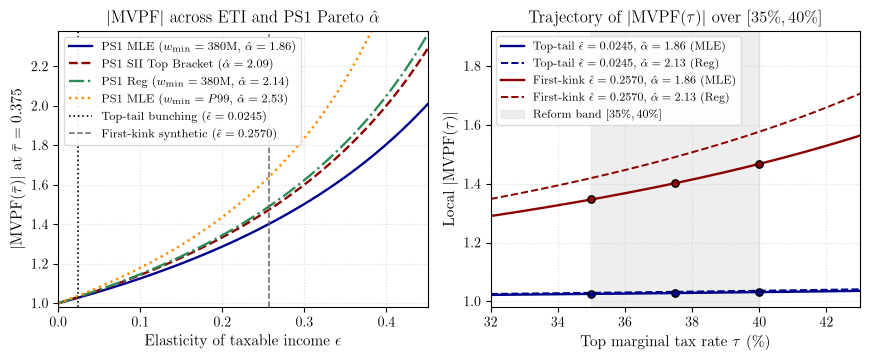

In [8]:
alpha_plot_dict = {
    r"PS1 MLE ($w_{\min}=380\mathrm{M}$, $\hat{\alpha}=1.86$)": 1.859,
    r"PS1 SII Top Bracket ($\hat{\alpha}=2.09$)": 2.085,
    r"PS1 Reg ($w_{\min}=380\mathrm{M}$, $\hat{\alpha}=2.14$)": 2.135,
    r"PS1 MLE ($w_{\min}=P99$, $\hat{\alpha}=2.53$)": 2.531,
}
fig2, axes2 = plt.subplots(1, 2, figsize=(8.8, 3.7))
plot_mvpf_calibration(
    alpha_plot_dict, eps_top=fit_150_mode["epsilon"], eps_kink1=fit_kink1["epsilon"],
    tau0=0.40, tau1=0.35, fig=fig2, axes=axes2
)
save_fig(FIGURES_DIR / "p3/p3_mvpf_calibration.pdf", fig=fig2)
plt.show()